In [39]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [40]:
import numpy as np
import random
import time

import sys, os, pathlib
REPO_DIR = pathlib.Path(os.path.dirname(os.path.abspath(os.getcwd()))); print(f"Repo: {str(REPO_DIR)}")
sys.path.insert(0, str(REPO_DIR / "src"))

from traffic_flow.paths import *
from traffic_flow.model.simulation import *
from traffic_flow.solvers.calibration import *
from traffic_flow.results.plots import Plotter, plot_velocity_comparison
from traffic_flow.inputs.scenario import prepare_traffic_data

from traffic_flow import load_scenario, calibrate
from traffic_flow.config import CalibrationConfig
from traffic_flow.pipeline import simulate

Repo: /Users/tristanchaang/MIT/UROP-Traffic/mpc-traffic-flow


In [41]:
def format_time(start_hour, minutes):
    hour, minute = divmod(int(start_hour * 60 + minutes), 60)
    return f"{hour % 24:02d}:{minute:02d}"

In [42]:
from traffic_flow.config import RampMapping

real_data = True

if real_data:
    # #### I-24 Data
    DATE = "11_28"
    i24_data_path = REPO_DIR / "data" / "i24" / f"i24_{DATE}"

    q_hat: time_space = np.load(i24_data_path / "q_hat.npy")#[240:270, :]
    p_hat: time_space = np.load(i24_data_path / "rho_hat.npy")#[240:270, :]

    lane_map = np.load(i24_data_path / "lane_mapping.npy")
    lane_mapping = {i: float(lane_map[i+1]) for i in range(len(lane_map)-2)}
    ramp_mapping: RampMapping = {"on_ramps": np.load(i24_data_path / "on_ramp_mapping.npy")[1:-1], "off_ramps": np.load(i24_data_path / "off_ramp_mapping.npy")[1:-1]}

    print("on_ramps:", list(map(int, ramp_mapping["on_ramps"])))
    print("off_ramps:", list(map(int, ramp_mapping["off_ramps"])))
    print("lanes:", list(map(lambda x: round(x, 2), lane_mapping.values())))
else:
    q_hat: time_space = np.load(REPO_DIR / "data" / "q_synthetic.npy") #np.load("data/flow_10sec_400m_1hr.npy")
    p_hat: time_space = np.load(REPO_DIR / "data" / "p_synthetic.npy") #np.load("data/density_10sec_400m_1hr.npy")

p_hat: time_space = np.clip(p_hat, 1e-3, None)
q_hat: time_space = np.clip(q_hat, 1e-3, None)
v_hat = q_hat / p_hat
flattened_q_hat = q_hat.flatten()
print(f"{flattened_q_hat.max() = }")
flattened_rho_hat = p_hat.flatten()
C_i = np.mean(np.sort(flattened_q_hat)[-5:]) # largest 5 values of q_hat, averaged
print(f"{C_i = }")
K = len(flattened_rho_hat)
print(f"{K = }")

on_ramps: [0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1]
off_ramps: [0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0]
lanes: [4.0, 4.0, 4.0, 4.35, 5.0, 5.0, 5.0, 5.0, 4.86, 4.0, 4.0, 4.05, 4.51, 4.0]
flattened_q_hat.max() = 8091.98009999998
C_i = 7532.372340000019
K = 5760


In [43]:
if not real_data:
    downstream_density = np.full(p_hat.shape[0], 0)
    data_inflow = np.array([5500 if i in range(20, 20 + 90) else 4000 for i in range(p_hat.shape[0])])
    # np.save(REPO_DIR / "data" / "downstream_density_synthetic.npy", downstream_density)
    # np.save(REPO_DIR / "data" / "inflow_synthetic.npy", data_inflow)
    p = Plotter(2, 1, figsize=(10, 5))
    p[0].plot(downstream_density, label="Downstream Density")
    p[1].plot(data_inflow, label="Upstream Inflow")
    p.show()

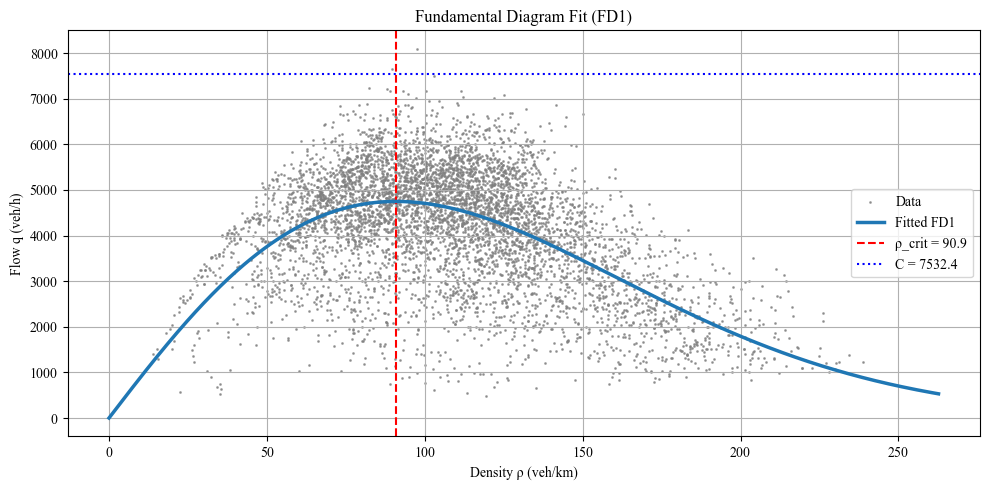

{'rho_crit': 90.9089566919478, 'V_free': 90.32182804407725, 'a': 1.8254228618304158, 'C': 7532.372340000019, 'Q_fd1': <function fit_fd1.<locals>.Q_fd1 at 0x107952320>}


In [ ]:
print(fit_fd1(flattened_rho_hat, flattened_q_hat))

In [45]:
print(f"Bounds on rho: {p_hat.min()} to {p_hat.max()}")
print(f"Bounds on q: {q_hat.min()} to {q_hat.max()}")
print(f"Bounds on v: {v_hat.min()} to {v_hat.max()}")

Bounds on rho: 14.00999575 to 238.81997374999997
Bounds on q: 493.0839000000909 to 8091.98009999998
Bounds on v: 4.099431208657852 to 116.22656577073002


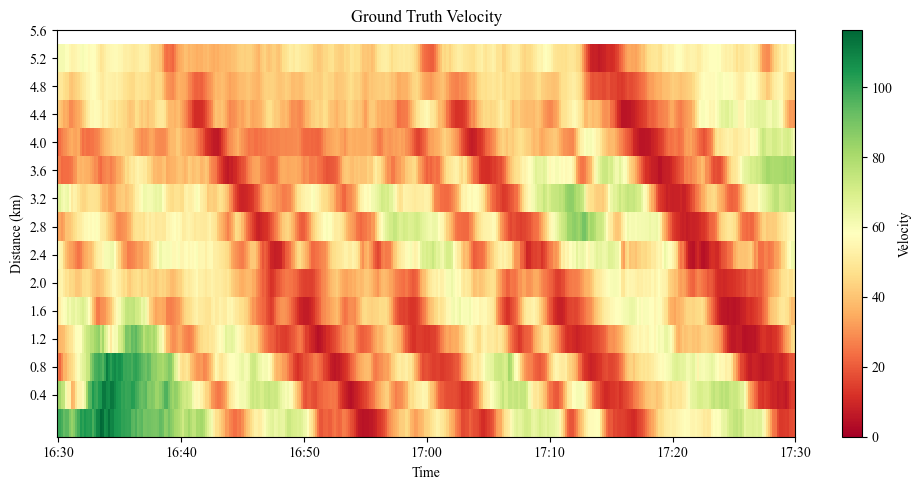

In [46]:
start_wallclock_time = 16.5

# Convert time steps to wall clock time
time_steps = v_hat.shape[0]+1
time_ticks = list(range(0, time_steps, int(time_steps / 6)))
# Correct - each step is 10 seconds = 10/60 minutes
tick_minutes = [i * 10 / 60 for i in time_ticks]
time_labels = [format_time(start_wallclock_time, m) for m in tick_minutes]

# Convert space steps to km
space_steps = v_hat.shape[1]
space_labels = [f"{(i * 400) / 1000:.1f}" for i in range(1, space_steps-1, int(space_steps / 10))]
space_ticks = list(range(1, space_steps-1, int(space_steps / 10)))

p = Plotter(1, 1)
p.fig.colorbar(p[0].imshow(v_hat[:,1:-1].T, aspect="auto", origin="lower", cmap="RdYlGn", interpolation="none", vmin=0),
  label="Velocity")
p[0].set(title='Ground Truth Velocity', xlabel='Time', ylabel='Distance (km)',
        xticks=time_ticks, xticklabels=time_labels, yticks=space_ticks, yticklabels=space_labels)
p.show()

In [47]:
scenario = load_scenario("i24", DATE)
spec, traffic = scenario.spec, scenario.traffic

include_ramping = True

In [49]:
random.seed(1)
np.random.seed(1)

calibration_config = CalibrationConfig(
    include_ramping=include_ramping,
    ramp_mapping=ramp_mapping,
)

start = time.time()
params = calibrate(scenario, calibration_config)
print(f"Calibration took {time.time() - start:.2f} seconds")

seg 0 is not an off-ramp, fixing beta to 1e-3
seg 1 is not an off-ramp, fixing beta to 1e-3
seg 2 is not an off-ramp, fixing beta to 1e-3
seg 3 is not an off-ramp, fixing beta to 1e-3
seg 4 is not an off-ramp, fixing beta to 1e-3
seg 5 is not an off-ramp, fixing beta to 1e-3
seg 6 is not an off-ramp, fixing beta to 1e-3
seg 7 is not an off-ramp, fixing beta to 1e-3
seg 8 is not an off-ramp, fixing beta to 1e-3
seg 10 is not an off-ramp, fixing beta to 1e-3
seg 12 is not an off-ramp, fixing beta to 1e-3
seg 13 is not an off-ramp, fixing beta to 1e-3
Ipopt 3.14.20: max_iter=20000
acceptable_constr_viol_tol=1e-12
constr_viol_tol=1e-12


******************************************************************************
This program contains Ipopt, a library for large-scale nonlinear optimization.
 Ipopt is released as open source code under the Eclipse Public License (EPL).
         For more information visit https://github.com/coin-or/Ipopt
****************************************************

In [ ]:
simulation = simulate(scenario, params, real_data=True)

assert simulation.density[:-1].shape == traffic.density.shape
assert simulation.velocity[:-1].shape == traffic.velocity.shape

In [51]:
# np.save(RESULTS_DIR/"upstream_flow.npy", smooth_inflow(q_hat[:, 0]) if smoothing else q_hat[:, 0])
# np.save(RESULTS_DIR/"downstream_density.npy", smooth_inflow(p_hat[:, -1]) if smoothing else p_hat[:, -1])

In [52]:
comparisons = {
    "Velocity": (
        traffic.velocity,
        simulation.velocity[:-1],
        "km/hr",
    ),
    "Density": (
        traffic.density * traffic.lanes,
        simulation.density[:-1] * traffic.lanes,
        "veh/km",
    ),
    "Flow": (
        traffic.flow,
        simulation.flow_per_lane[:-1] * traffic.lanes,
        "veh/hr",
    ),
}

In [53]:
# # Save everything
# tau_array = results["tau"]
# K_array = results["K"]
# eta_high_array = results["eta_high"]
# rho_crit_array = results["rho_crit"]
# v_free_array = results["v_free"]
# a_array = results["a"]
# num_lanes_array = results["num_lanes"]
# # if include_ramping:
#     # gamma_array = results["gamma"]
# beta_array = results["beta"]
# r_inflow_array = results["r_inflow"]
# v_pred_array = results["v_pred"]
# rho_pred_array = results["rho_pred"]
# q_array = v_pred_array * rho_pred_array

# np.save(f"{RESULTS_DIR}/tau.npy", tau_array)
# np.save(f"{RESULTS_DIR}/K.npy", K_array)
# np.save(f"{RESULTS_DIR}/eta_high.npy", eta_high_array)
# np.save(f"{RESULTS_DIR}/rho_crit.npy", rho_crit_array)
# np.save(f"{RESULTS_DIR}/v_free.npy", v_free_array)
# np.save(f"{RESULTS_DIR}/a.npy", a_array)
# np.save(f"{RESULTS_DIR}/num_lanes.npy", num_lanes_array)
# np.save(f"{RESULTS_DIR}/q_pred.npy", q_array)
# np.save(f"{RESULTS_DIR}/v_pred.npy", v_pred_array)
# np.save(f"{RESULTS_DIR}/rho_pred.npy", rho_pred_array)
# # np.save("r_array.npy", r_array)
# # if include_ramping:
#     # np.save("gamma_array.npy", gamma_array)
# np.save(f"{RESULTS_DIR}/beta_array.npy", beta_array)
# np.save(f"{RESULTS_DIR}/r_inflow_array.npy", r_inflow_array)

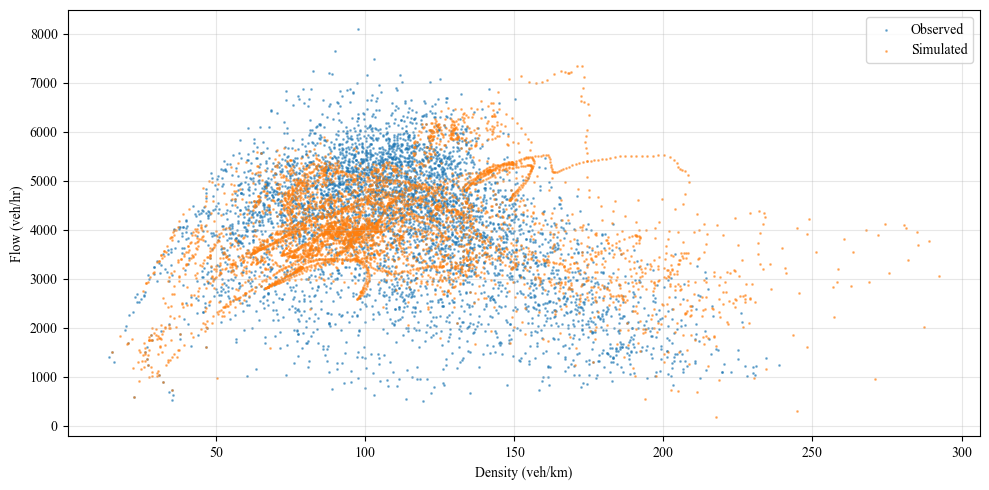

In [54]:
p = Plotter(1, 1)

for i, label in enumerate(("Observed", "Simulated")):
    p[0].scatter(
        comparisons["Density"][i].ravel(),
        comparisons["Flow"][i].ravel(),
        label=label, s=1, alpha=0.5,
    )

p[0].set(xlabel="Density (veh/km)", ylabel="Flow (veh/hr)")
p[0].grid(alpha=0.3)
p.show()

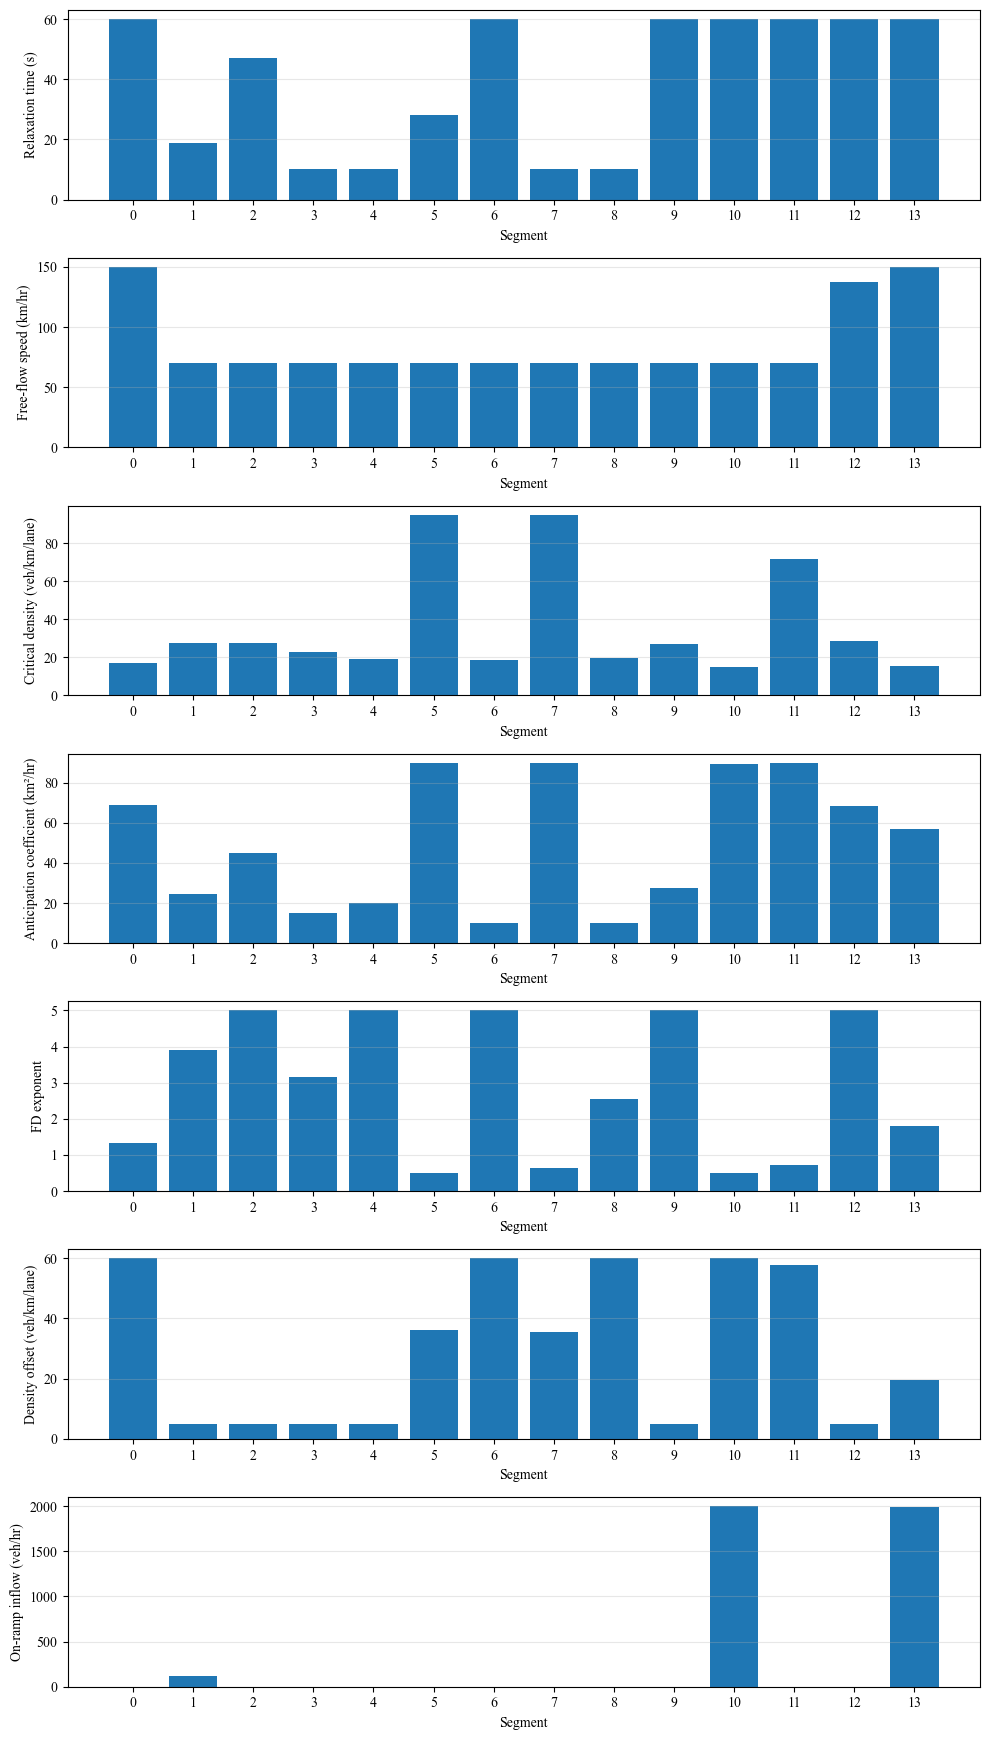

In [55]:
parameter_plots = {
    "Relaxation time (s)": params["tau"] * 3600,
    "Free-flow speed (km/hr)": params["v_free"],
    "Critical density (veh/km/lane)": params["p_crit"],
    "Anticipation coefficient (km²/hr)": params["eta_high"],
    "FD exponent": params["a"],
    "Density offset (veh/km/lane)": params["K"],
}
if calibration_config.include_ramping:
    parameter_plots["On-ramp inflow (veh/hr)"] = params["r"]

p = Plotter(len(parameter_plots), 1, figsize=(10, 2.5 * len(parameter_plots)))
segments = np.arange(spec.num_segments)

for ax, (label, values) in zip(p, parameter_plots.items()):
    ax.bar(segments, values)
    ax.set(xlabel="Segment", ylabel=label, xticks=segments)
    ax.grid(axis="y", alpha=0.3)

p.show()

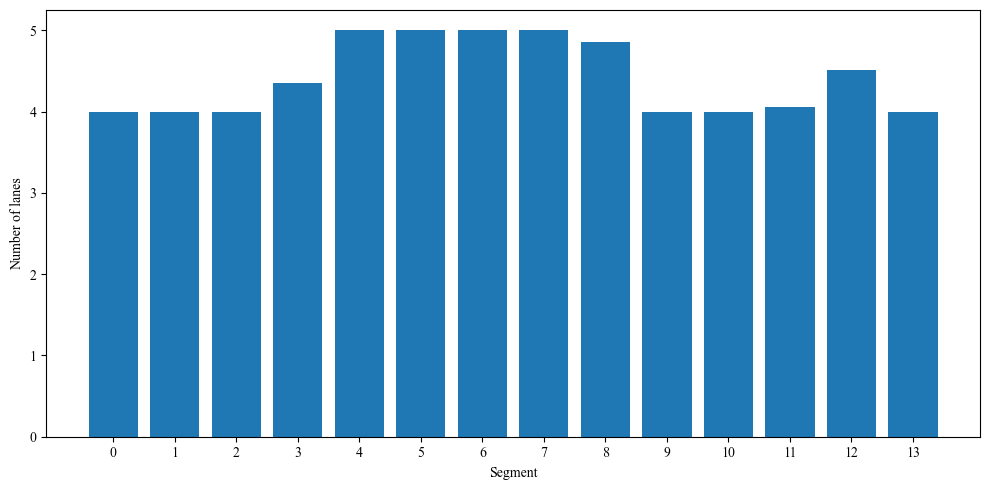

In [56]:
p = Plotter(1, 1)
p[0].bar(np.arange(spec.num_segments), traffic.lanes)
p[0].set(xlabel="Segment", ylabel="Number of lanes", xticks=np.arange(spec.num_segments))
p.show()

In [ ]:
from traffic_flow.results.analysis import mape, rmse
from traffic_flow.console import print_table

print_table(headers=["Quantity", "MAPE (%)", "RMSE", "RMSE unit"], data=[
    [name, f"{mape(observed, predicted):.2f}",
        f"{rmse(observed, predicted):.2f}", unit]
    for name, (observed, predicted, unit) in comparisons.items()
])

+------------+------------+---------+-------------+
| Quantity   |   MAPE (%) |    RMSE | RMSE unit   |
+============+============+=========+=============+
| Velocity   |      34.51 |   13.03 | km/hr       |
| Density    |      24.86 |   34.26 | veh/km      |
| Flow       |      30.61 | 1204.48 | veh/hr      |
+------------+------------+---------+-------------+


In [59]:
# np.save(f"{RESULTS_DIR}/v_sim.npy", v_sim)

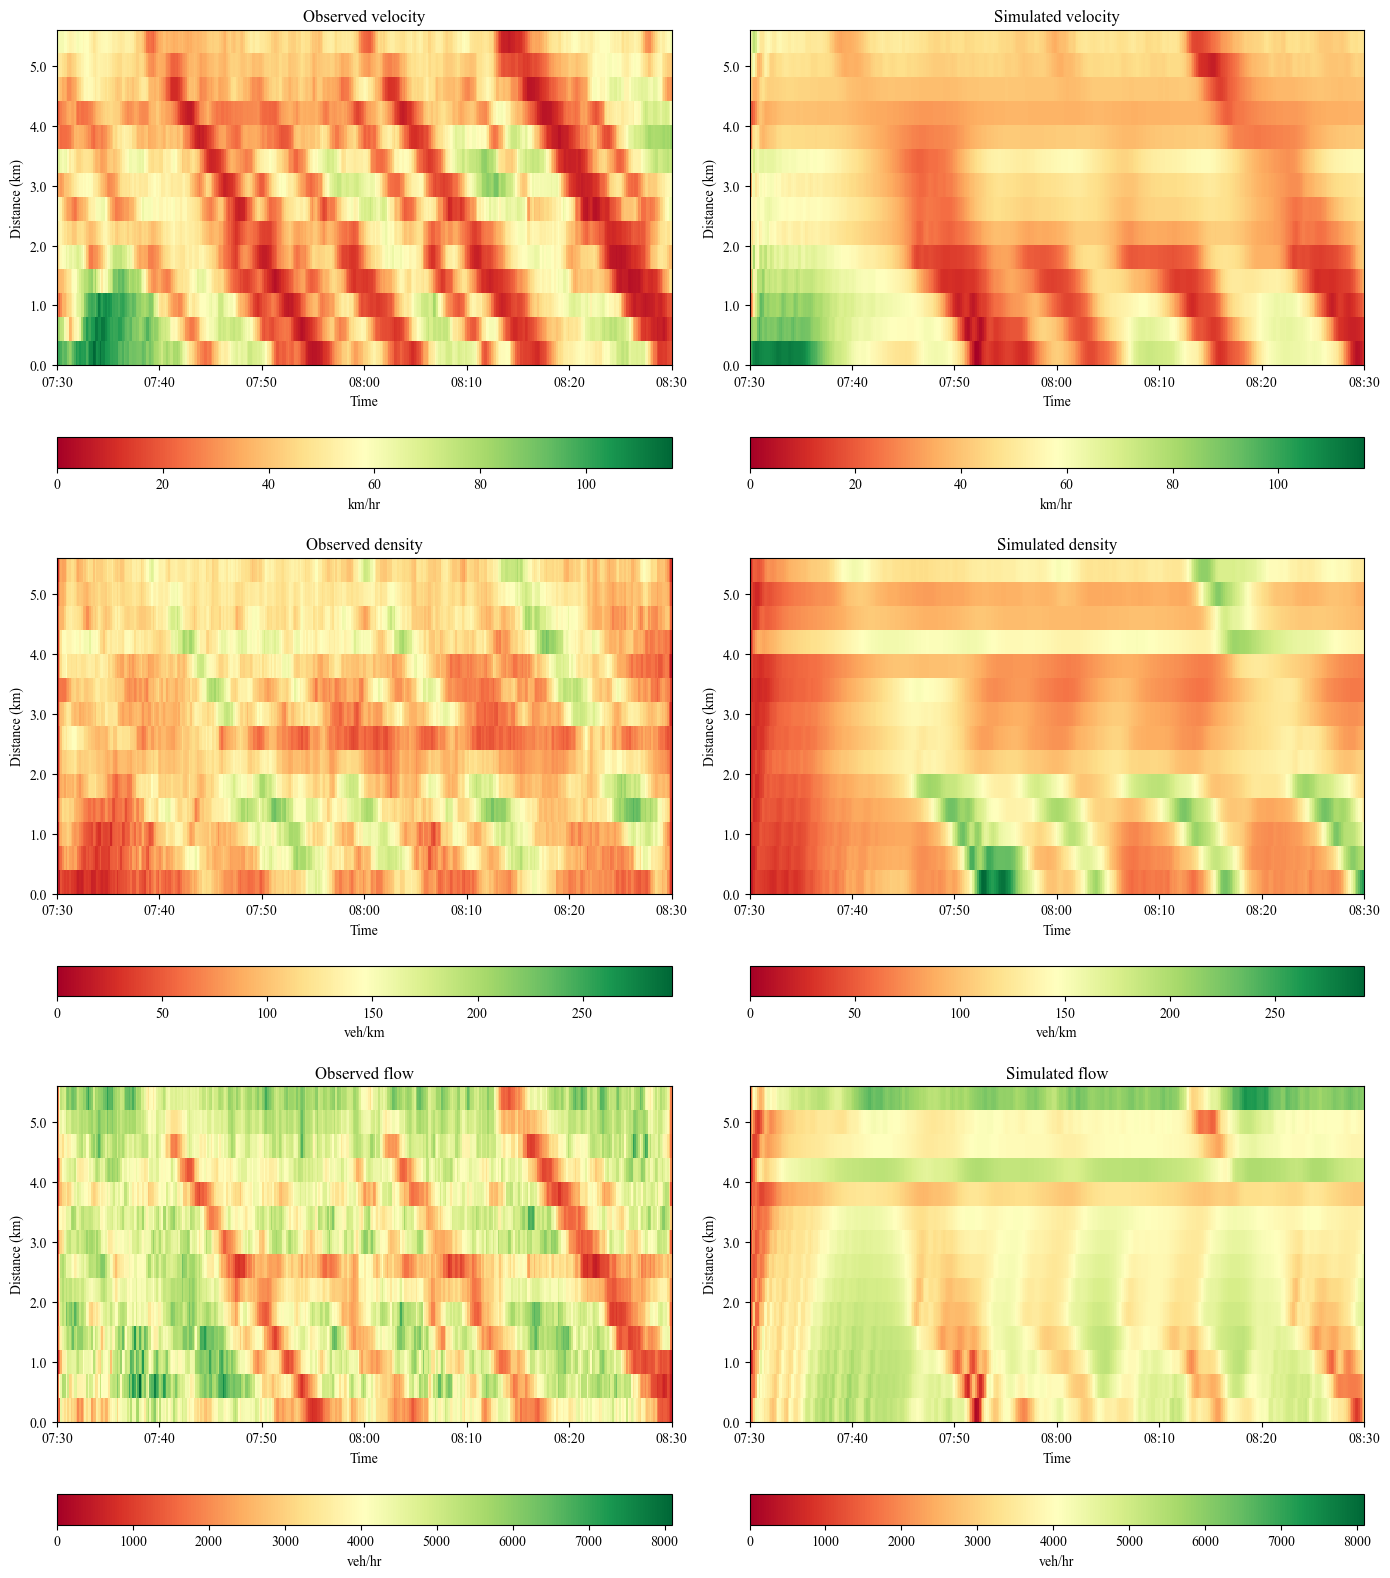

In [60]:
p = Plotter(3, 2, figsize=(14, 16))

for row, (name, (observed, predicted, unit)) in enumerate(comparisons.items()):
    vmax = float(max(observed.max(), predicted.max()))

    for col, (label, values) in enumerate([("Observed", observed), ("Simulated", predicted)]):
        p[row, col].plot_time_space(
            values, spec, spec.start_hour, vmax,
            title=f"{label} {name.lower()}",
            colorbar=("h", unit), cmap="RdYlGn",
        )

p.show()

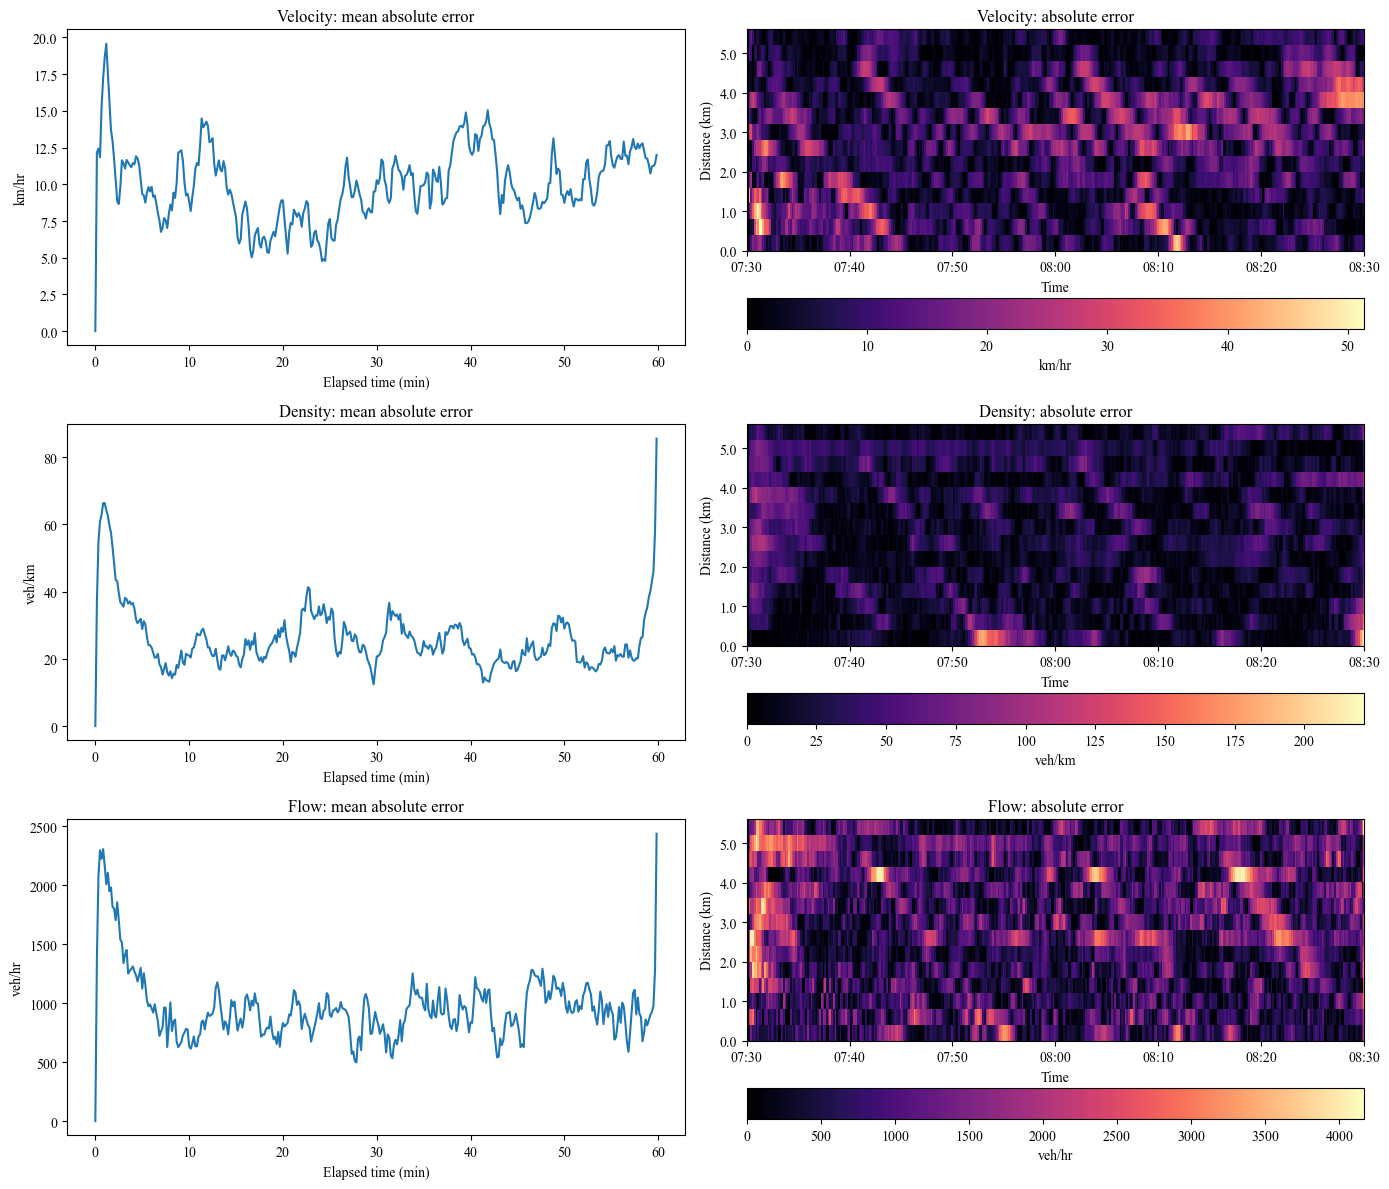

In [61]:
p = Plotter(3, 2, figsize=(14, 12))

for row, (name, (observed, predicted, unit)) in enumerate(comparisons.items()):
    error = np.abs(observed - predicted)
    minutes = np.arange(len(error)) * spec.time_step * 60

    p[row, 0].plot(minutes, error.mean(axis=1))
    p[row, 0].set(
        title=f"{name}: mean absolute error",
        xlabel="Elapsed time (min)",
        ylabel=unit,
    )

    p[row, 1].plot_time_space(
        error, spec, spec.start_hour,
        vmax=float(error.max()) or 1.0,
        title=f"{name}: absolute error",
        colorbar=("h", unit), cmap="magma",
    )

p.show()

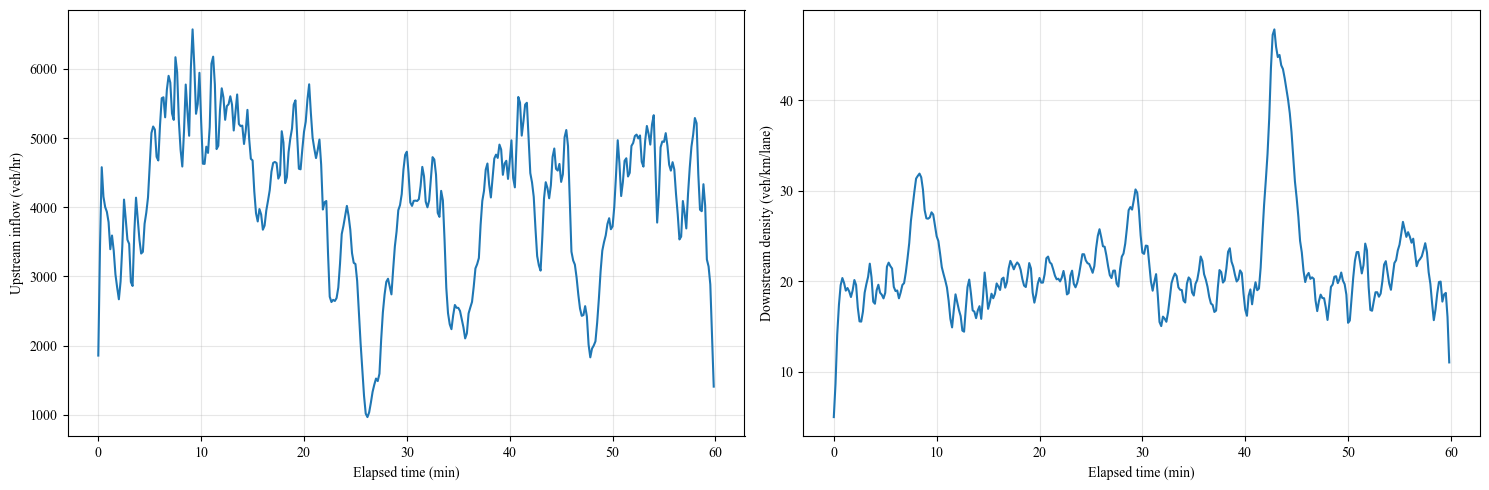

In [62]:
boundaries = {
    "Upstream inflow (veh/hr)": traffic.inflow,
    "Downstream density (veh/km/lane)": traffic.downstream_density,
}

p = Plotter(1, 2)

for ax, (label, values) in zip(p, boundaries.items()):
    minutes = np.arange(len(values)) * spec.time_step * 60
    ax.plot(minutes, values)
    ax.set(xlabel="Elapsed time (min)", ylabel=label)
    ax.grid(alpha=0.3)

p.show()

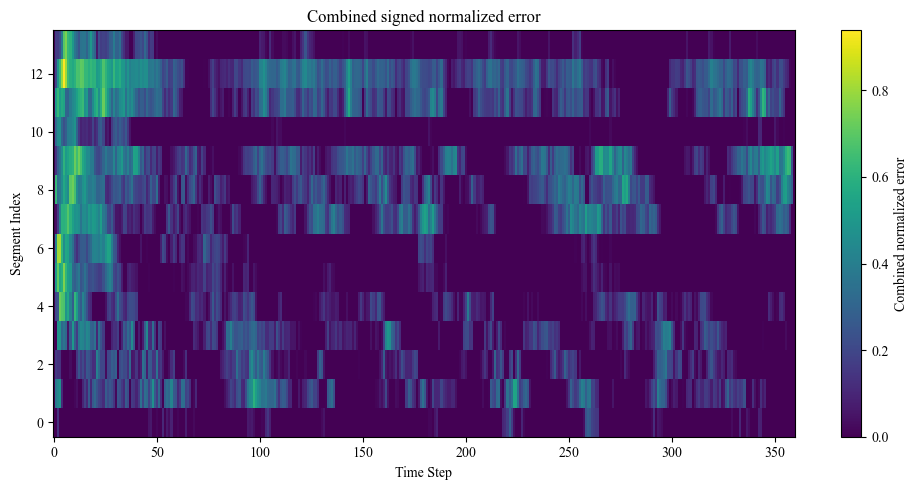

In [ ]:
diff = sum(
  ((observed - predicted) / observed.max()
  for observed, predicted, _ in comparisons.values()), 
  np.array(0)
)

p = Plotter(1, 1)
image = p[0].imshow(diff.T, aspect="auto", origin="lower", cmap="viridis", interpolation="none", vmin=0)
p.fig.colorbar(image, ax=p[0], label="Combined normalized error")
p[0].set(title="Combined signed normalized error", xlabel="Time Step", ylabel="Segment Index")
p.show()